# Subsecuencia palindrómica más larga

Buscar la subsecuencia más larga de una cadena que se lee igual al derecho y al revés (sus letras no tienen por qué estar seguidas). $L[i][j]$ es la longitud de la más larga dentro de $s_i \dots s_j$:

$$L[i][i] = 1, \qquad L[i][j] = \begin{cases} L[i+1][j-1] + 2 & \text{si } s_i = s_j \\ \max(L[i+1][j],\ L[i][j-1]) & \text{si no} \end{cases}$$

Se rellena por intervalos de longitud creciente y cuesta $O(n^2)$ en tiempo y memoria, frente a las $2^n$ subsecuencias.

## 1. Tabla y reconstrucción

Rellenar la tabla $L$ y reconstruir una subsecuencia palindrómica de longitud máxima recorriéndola desde $L[0][n-1]$: si los extremos coinciden se quedan los dos y si no se avanza hacia la casilla mayor. Dibujar la tabla de `"abracadabra"` como mapa de calor.

abracadabra    -> 'aradara' (7)
programacion   -> 'oamao' (5)
reconocer      -> 'reconocer' (9)
abcd           -> 'd' (1)


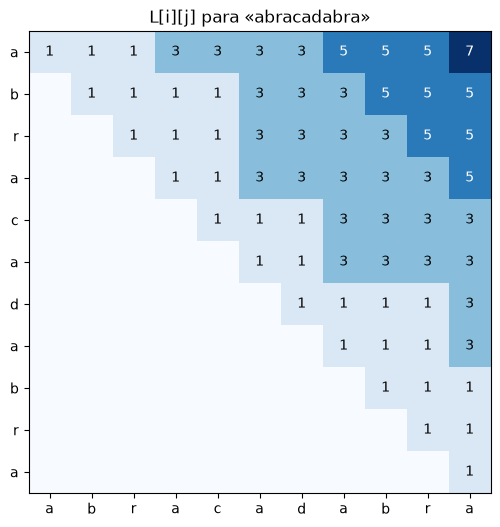

In [1]:
import matplotlib.pyplot as plt

def tabla_lps(s):
    n = len(s)
    L = [[0] * n for _ in range(n)]
    for i in range(n - 1, -1, -1):
        L[i][i] = 1
        for j in range(i + 1, n):
            if s[i] == s[j]:
                L[i][j] = L[i + 1][j - 1] + 2
            else:
                L[i][j] = max(L[i + 1][j], L[i][j - 1])
    return L

def lps(s):
    if not s:
        return ""
    L = tabla_lps(s)
    izquierda, centro, i, j = [], "", 0, len(s) - 1
    while i <= j:
        if i == j:
            centro = s[i]
            break
        if s[i] == s[j]:
            izquierda.append(s[i])
            i, j = i + 1, j - 1
        elif L[i + 1][j] >= L[i][j - 1]:
            i += 1
        else:
            j -= 1
    return "".join(izquierda) + centro + "".join(reversed(izquierda))

for s in ["abracadabra", "programacion", "reconocer", "abcd"]:
    print(f"{s:14} -> {lps(s)!r} ({tabla_lps(s)[0][-1]})")

s = "abracadabra"
L = tabla_lps(s)
fig, eje = plt.subplots(figsize=(6, 6))
eje.imshow(L, cmap="Blues")
for i in range(len(s)):
    for j in range(i, len(s)):
        eje.text(j, i, L[i][j], ha="center", va="center", color="white" if L[i][j] > L[0][-1] / 2 else "black")
eje.set_xticks(range(len(s)), list(s))
eje.set_yticks(range(len(s)), list(s))
eje.set_title("L[i][j] para «abracadabra»")
plt.show()

## 2. Comprobación contra fuerza bruta

Para cadenas aleatorias cortas, probar las subsecuencias de mayor a menor longitud con `itertools.combinations` hasta encontrar un palíndromo, y comprobar que la longitud coincide y que la reconstrucción es de verdad un palíndromo y una subsecuencia.

In [2]:
import random
from itertools import combinations

def es_subsecuencia(t, s):
    resto = iter(s)
    return all(c in resto for c in t)

def lps_fuerza_bruta(s):
    return next(r for r in range(len(s), -1, -1)
                if any(c == c[::-1] for c in combinations(s, r)))

random.seed(1)
for _ in range(500):
    s = "".join(random.choice("abc") for _ in range(random.randint(0, 12)))
    p = lps(s)
    assert len(p) == lps_fuerza_bruta(s) and p == p[::-1] and es_subsecuencia(p, s)

## 3. Relación con la subsecuencia común más larga

Una subsecuencia palindrómica de $s$ también es subsecuencia de $s$ invertida, así que la longitud de la más larga es la de la subsecuencia común más larga (LCS) de $s$ y `s[::-1]`. Implementar la LCS con una fila y comprobar que dan lo mismo.

In [3]:
def lcs(a, b):
    fila = [0] * (len(b) + 1)
    for x in a:
        nueva = [0]
        for j, y in enumerate(b, 1):
            nueva.append(fila[j - 1] + 1 if x == y else max(fila[j], nueva[j - 1]))
        fila = nueva
    return fila[-1]

random.seed(2)
for _ in range(500):
    s = "".join(random.choice("abcd") for _ in range(random.randint(1, 40)))
    assert lcs(s, s[::-1]) == tabla_lps(s)[0][-1]
print(lcs("programacion", "programacion"[::-1]))

5


## 4. Mínimo de inserciones para formar un palíndromo

Cada letra que no está en la subsecuencia palindrómica más larga necesita una pareja, así que el mínimo de letras que hay que insertar es $n - L[0][n-1]$. Construir el palíndromo insertando esas letras (se recorre como en la reconstrucción, añadiendo una copia de la letra que sobra en el lado contrario) y comprobar que es un palíndromo, que contiene a $s$ como subsecuencia y que tiene la longitud esperada. Comprobar el mínimo con una búsqueda en anchura sobre inserciones para cadenas cortas.

In [4]:
from collections import deque

def palindromo_con_inserciones(s):
    if not s:
        return ""
    L = tabla_lps(s)
    izquierda, centro, i, j = [], "", 0, len(s) - 1
    while i <= j:
        if i == j:
            centro = s[i]
            break
        if s[i] == s[j]:
            izquierda.append(s[i])
            i, j = i + 1, j - 1
        elif L[i + 1][j] >= L[i][j - 1]:
            izquierda.append(s[i])  # s[i] no tiene pareja: se copia al otro lado
            i += 1
        else:
            izquierda.append(s[j])
            j -= 1
    return "".join(izquierda) + centro + "".join(reversed(izquierda))

def inserciones_bfs(s):
    letras, vistos, cola = set(s), {s}, deque([(s, 0)])
    while cola:
        t, k = cola.popleft()
        if t == t[::-1]:
            return k
        for pos in range(len(t) + 1):
            for c in letras:
                u = t[:pos] + c + t[pos:]
                if u not in vistos:
                    vistos.add(u)
                    cola.append((u, k + 1))

random.seed(3)
for _ in range(200):
    s = "".join(random.choice("ab") for _ in range(random.randint(0, 7)))
    p = palindromo_con_inserciones(s)
    minimo = len(s) - (tabla_lps(s)[0][-1] if s else 0)
    assert p == p[::-1] and es_subsecuencia(s, p) and len(p) == len(s) + minimo
    assert minimo == inserciones_bfs(s)

for s in ["mar", "abcd", "cabaleta"]:
    print(f"{s} -> {palindromo_con_inserciones(s)}")

mar -> maram
abcd -> abcdcba
cabaleta -> cabaletelabac


## 5. Subsecuencia frente a subcadena

Si las letras tienen que estar seguidas (subcadena palindrómica más larga), basta con expandir desde cada uno de los $2n - 1$ centros posibles mientras los extremos coincidan, en $O(n^2)$. Comprobarlo contra fuerza bruta y comparar las dos respuestas en algunas frases.

In [5]:
def subcadena_palindromica(s):
    mejor = ""
    for centro in range(2 * len(s) - 1):
        i, j = centro // 2, (centro + 1) // 2
        while i >= 0 and j < len(s) and s[i] == s[j]:
            i, j = i - 1, j + 1
        if j - i - 1 > len(mejor):
            mejor = s[i + 1:j]
    return mejor

def subcadena_fuerza_bruta(s):
    return max((len(s[i:j]) for i in range(len(s)) for j in range(i + 1, len(s) + 1) if s[i:j] == s[i:j][::-1]),
               default=0)

random.seed(4)
for _ in range(500):
    s = "".join(random.choice("ab") for _ in range(random.randint(0, 15)))
    t = subcadena_palindromica(s)
    assert len(t) == subcadena_fuerza_bruta(s) and t == t[::-1] and t in s

for s in ["anitalavalatina", "dabale arroz a la zorra el abad", "programacion dinamica"]:
    print(f"{s!r}: subcadena {subcadena_palindromica(s)!r}, subsecuencia {lps(s)!r}")

'anitalavalatina': subcadena 'anitalavalatina', subsecuencia 'anitalavalatina'
'dabale arroz a la zorra el abad': subcadena 'aba', subsecuencia 'dabale arroz ala zorra elabad'
'programacion dinamica': subcadena 'ama', subsecuencia 'acininica'
